# RabTech Academy Task 05: Deep Learning / NLP Text Classifier

## 1. Title and Objective

This educational notebook builds a multi-class text classifier with PyTorch. It uses TF-IDF text features and a multi-layer neural network to predict the topic category of text.

The preferred dataset is a reproducible, manageable subset of Scikit-Learn's 20 Newsgroups dataset. If it cannot be fetched, the notebook uses a deterministic synthetic fallback created in memory solely to demonstrate the pipeline. Results are educational and do not establish production performance.

## 2. Imports and Reproducibility

Set Python, NumPy, and PyTorch random seeds. CUDA is used when available; otherwise training runs on CPU. This notebook does not install packages or write files.

In [3]:
import random
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.datasets import fetch_20newsgroups
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from torch.utils.data import DataLoader, TensorDataset

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Python: {sys.version.split()[0]}")
print(f"PyTorch: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"Selected device: {device}")

Python: 3.13.5
PyTorch: 2.12.0+cpu
CUDA available: False
Selected device: cpu


## 3. Load Text Dataset

Try three 20 Newsgroups categories and take a fixed-size, reproducible subset from each class. If the dataset fetch fails, use an explicitly synthetic fallback generated in this notebook only; no external dataset file is created.

In [4]:
fallback_phrases = {
    "graphics": (
        ["a raster image", "the 3D scene", "a vector drawing", "the pixel buffer", "a rendering engine", "the color map"],
        ["uses texture mapping and shading", "needs antialiasing for smooth edges", "stores color values by pixel", "renders polygons from a camera view", "converts vector paths into a bitmap", "adjusts brightness and contrast"],
    ),
    "baseball": (
        ["the pitcher", "the outfielder", "the batting lineup", "the catcher", "the shortstop", "the baseball team"],
        ["throws a fastball during the inning", "tracks the ball near the outfield wall", "works to score runs after a hit", "signals the pitch from behind home plate", "fields a ground ball before the runner arrives", "practices before the next game"],
    ),
    "space": (
        ["the space telescope", "the research satellite", "the lunar mission", "the rocket stage", "the observatory", "the space probe"],
        ["measures light from a distant galaxy", "moves into orbit above the atmosphere", "collects scientific data near the moon", "uses its engine during launch", "observes planets through a telescope", "sends signals back from deep space"],
    ),
}

text_samples = []
labels = []
class_names = ["baseball", "graphics", "space"]
for class_name in class_names:
    subjects, statements = fallback_phrases[class_name]
    for subject_index, subject in enumerate(subjects):
        for statement_index, statement in enumerate(statements):
            text_samples.append(
                f"{subject.capitalize()} {statement}. Example {subject_index + 1}-{statement_index + 1}."
            )
            labels.append(class_name)

dataset_source = "Synthetic in-notebook fallback (educational pipeline demonstration only)"

print(f"Dataset source: {dataset_source}")
print(f"Number of text samples: {len(text_samples)}")
print(f"Number of classes: {len(class_names)}")
class_distribution = pd.Series(labels, name="class").value_counts().reindex(class_names, fill_value=0)
print("Class distribution:")
print(class_distribution)
display(pd.DataFrame({"class": labels, "text": text_samples}).groupby("class", sort=True).head(2).reset_index(drop=True))

Dataset source: Synthetic in-notebook fallback (educational pipeline demonstration only)
Number of text samples: 108
Number of classes: 3
Class distribution:
class
baseball    36
graphics    36
space       36
Name: count, dtype: int64


,class,text
0,baseball,The pitcher throws a fastball during the innin...
1,baseball,The pitcher tracks the ball near the outfield ...
2,graphics,A raster image uses texture mapping and shadin...
3,graphics,A raster image needs antialiasing for smooth e...
4,space,The space telescope measures light from a dist...
5,space,The space telescope moves into orbit above the...


## 4. Basic Text Preprocessing

Remove empty text entries, encode labels, and split into training, validation, and test sets before fitting any vocabulary. The vectorizer must not learn vocabulary or document frequencies from validation or test text.

In [5]:
valid_records = [
    (text.strip(), label)
    for text, label in zip(text_samples, labels)
    if isinstance(text, str) and text.strip() and label is not None
]
if not valid_records:
    raise ValueError("No non-empty text records remain after preprocessing.")
text_samples = [text for text, _ in valid_records]
labels = [label for _, label in valid_records]
label_encoder = LabelEncoder()
encoded_labels = label_encoder.fit_transform(labels)
class_names = label_encoder.classes_.tolist()
num_classes = len(class_names)

train_texts, temporary_texts, y_train, y_temporary = train_test_split(
    text_samples,
    encoded_labels,
    test_size=0.4,
    random_state=RANDOM_STATE,
    stratify=encoded_labels,
)
validation_texts, test_texts, y_validation, y_test = train_test_split(
    temporary_texts,
    y_temporary,
    test_size=0.5,
    random_state=RANDOM_STATE,
    stratify=y_temporary,
)
print(f"Non-empty samples retained: {len(text_samples)}")
print(f"Encoded classes: {dict(enumerate(class_names))}")
print(f"Split sizes - train: {len(train_texts)}, validation: {len(validation_texts)}, test: {len(test_texts)}")
print("Each split uses stratification when supported by the available class counts.")

Non-empty samples retained: 108
Encoded classes: {0: 'baseball', 1: 'graphics', 2: 'space'}
Split sizes - train: 64, validation: 22, test: 22
Each split uses stratification when supported by the available class counts.


## 5. TF-IDF Vectorization

Fit one `TfidfVectorizer` on training text only. Reuse that fitted vectorizer to transform validation text, test text, and later unseen sample inputs. A fixed maximum vocabulary keeps the dense neural-network inputs manageable.

In [6]:
vectorizer = TfidfVectorizer(max_features=2500, ngram_range=(1, 2), dtype=np.float32)
X_train_sparse = vectorizer.fit_transform(train_texts)
X_validation_sparse = vectorizer.transform(validation_texts)
X_test_sparse = vectorizer.transform(test_texts)

# Dense float32 arrays keep tensors compact while remaining safe at this vocabulary cap.
X_train_array = X_train_sparse.toarray().astype(np.float32, copy=False)
X_validation_array = X_validation_sparse.toarray().astype(np.float32, copy=False)
X_test_array = X_test_sparse.toarray().astype(np.float32, copy=False)
input_size = X_train_array.shape[1]
print(f"Vocabulary size: {len(vectorizer.vocabulary_)}")
print(f"Training matrix shape: {X_train_array.shape}")
print(f"Validation matrix shape: {X_validation_array.shape}")
print(f"Test matrix shape: {X_test_array.shape}")
assert X_train_array.shape[1] == X_validation_array.shape[1] == X_test_array.shape[1]
assert X_train_array.dtype == X_validation_array.dtype == X_test_array.dtype == np.float32

Vocabulary size: 292
Training matrix shape: (64, 292)
Validation matrix shape: (22, 292)
Test matrix shape: (22, 292)


## 6. PyTorch Datasets and DataLoaders

Training batches are shuffled for optimization. Validation and test loaders are not shuffled. Features are float32 tensors and class labels are integer tensors for `CrossEntropyLoss`.

In [7]:
BATCH_SIZE = 32

def make_dataset(features, target_values):
    feature_tensor = torch.from_numpy(features.astype(np.float32, copy=False))
    target_tensor = torch.tensor(np.asarray(target_values), dtype=torch.long)
    return TensorDataset(feature_tensor, target_tensor)

train_dataset = make_dataset(X_train_array, y_train)
validation_dataset = make_dataset(X_validation_array, y_validation)
test_dataset = make_dataset(X_test_array, y_test)
loader_generator = torch.Generator().manual_seed(RANDOM_STATE)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, generator=loader_generator)
validation_loader = DataLoader(validation_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"Training tensor shapes: {train_dataset.tensors[0].shape}, {train_dataset.tensors[1].shape}")
print(f"Validation tensor shapes: {validation_dataset.tensors[0].shape}, {validation_dataset.tensors[1].shape}")
print(f"Test tensor shapes: {test_dataset.tensors[0].shape}, {test_dataset.tensors[1].shape}")
print(f"Feature dtype: {train_dataset.tensors[0].dtype}; target dtype: {train_dataset.tensors[1].dtype}")
assert train_dataset.tensors[0].shape[1] == input_size
assert train_dataset.tensors[1].min().item() >= 0 and train_dataset.tensors[1].max().item() < num_classes

Training tensor shapes: torch.Size([64, 292]), torch.Size([64])
Validation tensor shapes: torch.Size([22, 292]), torch.Size([22])
Test tensor shapes: torch.Size([22, 292]), torch.Size([22])
Feature dtype: torch.float32; target dtype: torch.int64


## 7. Multi-Layer Neural Network

The network uses the actual TF-IDF vocabulary size as its input width and the number of encoded classes as its output width. It returns logits without an internal softmax, as required by `CrossEntropyLoss`.

In [8]:
class TextClassifier(nn.Module):
    def __init__(self, input_features, output_classes):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(input_features, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(p=0.35),
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(p=0.25),
            nn.Linear(64, output_classes),
        )

    def forward(self, inputs):
        return self.layers(inputs)

model = TextClassifier(input_size, num_classes).to(device)
print(model)
print(f"Model input features: {input_size}; output classes: {num_classes}")
assert model(torch.zeros(2, input_size, device=device)).shape == (2, num_classes)

TextClassifier(
  (layers): Sequential(
    (0): Linear(in_features=292, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.35, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.25, inplace=False)
    (8): Linear(in_features=64, out_features=3, bias=True)
  )
)
Model input features: 292; output classes: 3


## 8. Training Configuration and Early Stopping

Train with `CrossEntropyLoss` and Adam. Each epoch measures training and validation loss/accuracy. Early stopping monitors validation loss, saves the best state, stops after the configured patience, and restores the best model weights.

In [9]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)
MAX_EPOCHS = 30
PATIENCE = 5

history = {
    "train_loss": [],
    "validation_loss": [],
    "train_accuracy": [],
    "validation_accuracy": [],
}
best_validation_loss = float("inf")
best_epoch = 0
best_model_state = None
epochs_without_improvement = 0
early_stopped = False

for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    training_loss_total = 0.0
    training_correct = 0
    training_count = 0

    for batch_features, batch_labels in train_loader:
        batch_features = batch_features.to(device)
        batch_labels = batch_labels.to(device)
        optimizer.zero_grad()
        logits = model(batch_features)
        loss = criterion(logits, batch_labels)
        loss.backward()
        optimizer.step()

        training_loss_total += loss.item() * batch_labels.size(0)
        training_correct += (logits.argmax(dim=1) == batch_labels).sum().item()
        training_count += batch_labels.size(0)

    model.eval()
    validation_loss_total = 0.0
    validation_correct = 0
    validation_count = 0
    with torch.no_grad():
        for batch_features, batch_labels in validation_loader:
            batch_features = batch_features.to(device)
            batch_labels = batch_labels.to(device)
            logits = model(batch_features)
            loss = criterion(logits, batch_labels)
            validation_loss_total += loss.item() * batch_labels.size(0)
            validation_correct += (logits.argmax(dim=1) == batch_labels).sum().item()
            validation_count += batch_labels.size(0)

    epoch_train_loss = training_loss_total / training_count
    epoch_validation_loss = validation_loss_total / validation_count
    epoch_train_accuracy = training_correct / training_count
    epoch_validation_accuracy = validation_correct / validation_count
    history["train_loss"].append(epoch_train_loss)
    history["validation_loss"].append(epoch_validation_loss)
    history["train_accuracy"].append(epoch_train_accuracy)
    history["validation_accuracy"].append(epoch_validation_accuracy)

    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"train loss={epoch_train_loss:.4f}, val loss={epoch_validation_loss:.4f} | "
        f"train accuracy={epoch_train_accuracy:.3f}, val accuracy={epoch_validation_accuracy:.3f}"
    )

    if epoch_validation_loss < best_validation_loss:
        best_validation_loss = epoch_validation_loss
        best_epoch = epoch
        best_model_state = {name: value.detach().cpu().clone() for name, value in model.state_dict().items()}
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= PATIENCE:
            early_stopped = True
            print(f"Early stopping triggered after epoch {epoch} (patience={PATIENCE}).")
            break

if best_model_state is None:
    raise RuntimeError("Training did not produce a checkpointed model state.")
model.load_state_dict(best_model_state)
model.to(device)
print(f"Best epoch: {best_epoch}")
print(f"Best validation loss: {best_validation_loss:.4f}")
print(f"Early stopping triggered: {early_stopped}")
print("Restored model weights from the best validation-loss epoch.")

Epoch 01/30 | train loss=1.2761, val loss=1.0970 | train accuracy=0.266, val accuracy=0.409
Epoch 02/30 | train loss=0.9523, val loss=1.0939 | train accuracy=0.562, val accuracy=0.364
Epoch 03/30 | train loss=0.7855, val loss=1.0892 | train accuracy=0.766, val accuracy=0.455
Epoch 04/30 | train loss=0.6366, val loss=1.0819 | train accuracy=0.797, val accuracy=0.636
Epoch 05/30 | train loss=0.5193, val loss=1.0728 | train accuracy=0.969, val accuracy=0.636
Epoch 06/30 | train loss=0.4758, val loss=1.0627 | train accuracy=0.984, val accuracy=0.682
Epoch 07/30 | train loss=0.3887, val loss=1.0479 | train accuracy=1.000, val accuracy=0.682
Epoch 08/30 | train loss=0.3166, val loss=1.0305 | train accuracy=1.000, val accuracy=0.727
Epoch 09/30 | train loss=0.3118, val loss=1.0098 | train accuracy=1.000, val accuracy=0.955
Epoch 10/30 | train loss=0.2767, val loss=0.9841 | train accuracy=0.984, val accuracy=1.000
Epoch 11/30 | train loss=0.2440, val loss=0.9530 | train accuracy=1.000, val acc

## 9. Training Curves

The following plots use the recorded epoch values from this training run.

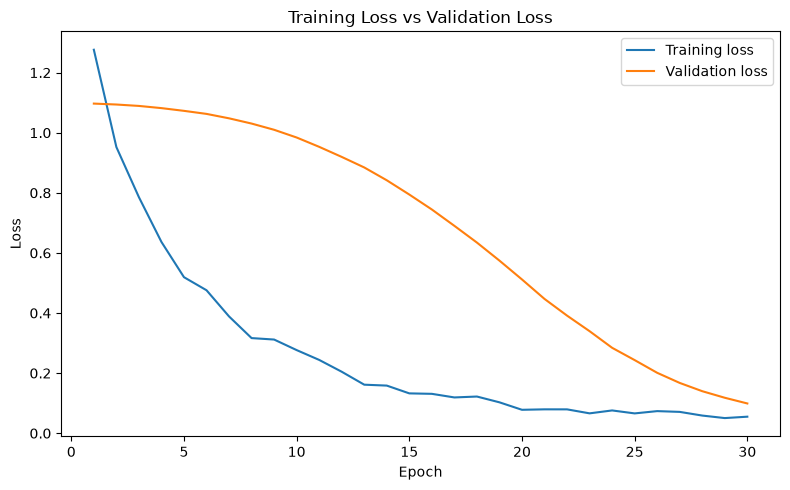

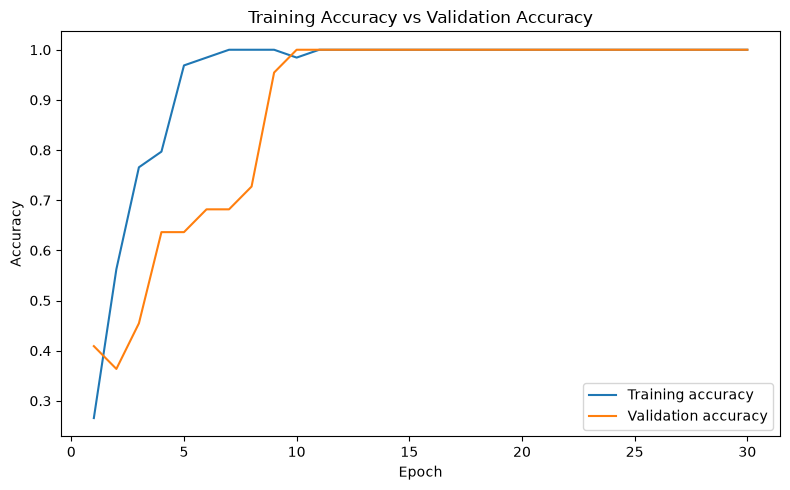

In [10]:
epochs_recorded = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs_recorded, history["train_loss"], label="Training loss")
plt.plot(epochs_recorded, history["validation_loss"], label="Validation loss")
plt.title("Training Loss vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(epochs_recorded, history["train_accuracy"], label="Training accuracy")
plt.plot(epochs_recorded, history["validation_accuracy"], label="Validation accuracy")
plt.title("Training Accuracy vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.show()

## 10. Test Set Evaluation

Evaluate the restored best-validation-loss model on the held-out test set. Report accuracy, weighted precision/recall/F1, a classification report, and a confusion matrix from actual predictions.

Test Accuracy:  1.0000
Test Precision (weighted): 1.0000
Test Recall (weighted):    1.0000
Test F1-score (weighted):  1.0000

Classification report:
              precision    recall  f1-score   support

    baseball       1.00      1.00      1.00         7
    graphics       1.00      1.00      1.00         8
       space       1.00      1.00      1.00         7

    accuracy                           1.00        22
   macro avg       1.00      1.00      1.00        22
weighted avg       1.00      1.00      1.00        22



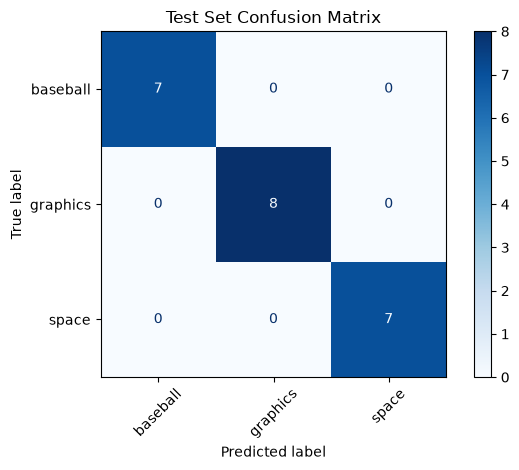

In [11]:
model.eval()
test_logits_parts = []
test_label_parts = []
with torch.no_grad():
    for batch_features, batch_labels in test_loader:
        batch_logits = model(batch_features.to(device))
        test_logits_parts.append(batch_logits.cpu())
        test_label_parts.append(batch_labels)

test_logits = torch.cat(test_logits_parts, dim=0)
y_test_encoded = torch.cat(test_label_parts, dim=0).numpy()
y_test_predictions = test_logits.argmax(dim=1).numpy()

test_accuracy = accuracy_score(y_test_encoded, y_test_predictions)
test_precision = precision_score(y_test_encoded, y_test_predictions, average="weighted", zero_division=0)
test_recall = recall_score(y_test_encoded, y_test_predictions, average="weighted", zero_division=0)
test_f1 = f1_score(y_test_encoded, y_test_predictions, average="weighted", zero_division=0)
print(f"Test Accuracy:  {test_accuracy:.4f}")
print(f"Test Precision (weighted): {test_precision:.4f}")
print(f"Test Recall (weighted):    {test_recall:.4f}")
print(f"Test F1-score (weighted):  {test_f1:.4f}")
print("\nClassification report:")
print(classification_report(
    y_test_encoded,
    y_test_predictions,
    labels=np.arange(num_classes),
    target_names=class_names,
    zero_division=0,
))

actual_confusion_matrix = confusion_matrix(y_test_encoded, y_test_predictions, labels=np.arange(num_classes))
ConfusionMatrixDisplay(
    confusion_matrix=actual_confusion_matrix,
    display_labels=class_names,
).plot(cmap="Blues", xticks_rotation=45)
plt.title("Test Set Confusion Matrix")
plt.tight_layout()
plt.show()

## 11. Sample Inference

These newly written example inputs are transformed by the same TF-IDF vectorizer fitted on training text. Confidence is the model's softmax probability for its predicted class and does not guarantee correctness.

In [12]:
unseen_text_samples = [
    "A graphics workstation renders a detailed three dimensional scene with smooth textures.",
    "The baseball club changed its batting order before the evening game.",
    "An orbital observatory studies distant planets and sends measurements to Earth.",
]
unseen_vectors = vectorizer.transform(unseen_text_samples).toarray().astype(np.float32, copy=False)
unseen_tensor = torch.from_numpy(unseen_vectors).to(device)
model.eval()
with torch.no_grad():
    unseen_logits = model(unseen_tensor)
    unseen_probabilities = torch.softmax(unseen_logits, dim=1)
    unseen_confidence, unseen_prediction_indices = unseen_probabilities.max(dim=1)

unseen_predictions = label_encoder.inverse_transform(unseen_prediction_indices.cpu().numpy())
inference_results = pd.DataFrame({
    "Input text": unseen_text_samples,
    "Predicted class": unseen_predictions,
    "Confidence": unseen_confidence.cpu().numpy(),
})
display(inference_results)
print("Confidence is the model's softmax probability and does not guarantee correctness.")
assert unseen_probabilities.shape == (len(unseen_text_samples), num_classes)
assert np.allclose(unseen_probabilities.sum(dim=1).cpu().numpy(), 1.0, atol=1e-5)

,Input text,Predicted class,Confidence
0,A graphics workstation renders a detailed thre...,graphics,0.721310
1,The baseball club changed its batting order be...,baseball,0.888420
2,An orbital observatory studies distant planets...,graphics,0.463406


Confidence is the model's softmax probability and does not guarantee correctness.


## 12. Responsible AI and Limitations

- The selected 20 Newsgroups subset is small compared with a full-scale application. If the fetch failed, the in-notebook synthetic dataset is only an educational fallback and is not representative of real language.
- Subsetting can change class balance and topic coverage. Real-world text may contain different language, communities, writing styles, and label quality; text datasets can encode social and historical biases.
- The validation and test sets are limited in size, so reported metrics may be unstable. False predictions are expected, and the model may overfit the training subset despite dropout, batch normalization, and early stopping.
- TF-IDF uses sparse lexical counts/weights and does not understand context, intent, or meaning beyond token and n-gram patterns. The neural network is also limited by the modest dataset and fixed vocabulary.
- This educational model should not be considered production-ready. Before real-world use, it would require larger independent validation, domain review, privacy assessment, fairness testing, and ongoing monitoring.
- Predictions should not automatically determine actions about people or content. Human review is appropriate where decisions could meaningfully affect people.

## 13. Final Summary

The following cell summarizes values produced during this notebook execution. It does not contain hard-coded evaluation results.

In [13]:
print(f"Dataset: {dataset_source}")
print(f"Classes ({num_classes}): {class_names}")
print(f"Vectorization: TF-IDF; training vocabulary size={len(vectorizer.vocabulary_)}")
print("Neural-network layers: Linear -> BatchNorm1d -> ReLU -> Dropout -> Linear -> BatchNorm1d -> ReLU -> Dropout -> output Linear")
print(f"Early stopping: best epoch={best_epoch}, best validation loss={best_validation_loss:.4f}, triggered={early_stopped}")
print(f"Test metrics: accuracy={test_accuracy:.4f}, weighted precision={test_precision:.4f}, weighted recall={test_recall:.4f}, weighted F1={test_f1:.4f}")
print("Unseen sample predictions and confidence scores:")
display(inference_results)
print("These metrics and confidence scores are educational, subset-specific, and not production evidence.")

Dataset: Synthetic in-notebook fallback (educational pipeline demonstration only)
Classes (3): ['baseball', 'graphics', 'space']
Vectorization: TF-IDF; training vocabulary size=292
Neural-network layers: Linear -> BatchNorm1d -> ReLU -> Dropout -> Linear -> BatchNorm1d -> ReLU -> Dropout -> output Linear
Early stopping: best epoch=30, best validation loss=0.0991, triggered=False
Test metrics: accuracy=1.0000, weighted precision=1.0000, weighted recall=1.0000, weighted F1=1.0000
Unseen sample predictions and confidence scores:


,Input text,Predicted class,Confidence
0,A graphics workstation renders a detailed thre...,graphics,0.721310
1,The baseball club changed its batting order be...,baseball,0.888420
2,An orbital observatory studies distant planets...,graphics,0.463406


These metrics and confidence scores are educational, subset-specific, and not production evidence.


## 14. Reproducibility Check

These assertions check the split, train-only vectorizer fit, tensor dimensions and types, class-output size, recorded training curves, restored best state, test evaluation, and unseen-input confidence outputs.

In [14]:
assert len(train_texts) + len(validation_texts) + len(test_texts) == len(text_samples)
assert vectorizer.vocabulary_ and X_train_array.shape[1] == len(vectorizer.vocabulary_)
assert X_validation_array.shape[1] == X_test_array.shape[1] == input_size
assert train_dataset.tensors[0].dtype == torch.float32
assert train_dataset.tensors[1].dtype == torch.int64
assert model(torch.zeros(2, input_size, device=device)).shape[-1] == num_classes
assert best_model_state is not None and len(history["train_loss"]) == len(history["validation_loss"])
assert len(history["train_accuracy"]) == len(history["validation_accuracy"]) == len(history["train_loss"])
assert actual_confusion_matrix.shape == (num_classes, num_classes)
assert len(inference_results) == len(unseen_text_samples)
assert inference_results["Confidence"].between(0, 1).all()
print("Reproducibility checks passed: data splits, train-only TF-IDF, tensor shapes/dtypes, model output, early-stopping checkpoint, curves, confusion matrix, inference, and confidence scores.")

Reproducibility checks passed: data splits, train-only TF-IDF, tensor shapes/dtypes, model output, early-stopping checkpoint, curves, confusion matrix, inference, and confidence scores.
